#  Частотная фильтрация и алиасинг


**Цель:** Увидеть, как пространственная частота объясняет размытие, резкость и артефакты уменьшения размера.

**Входные данные:** `images/source/fine_stripes.png`, `images/source/checkerboard.png`, `images/source/brick.png`

**Формула:** F(u,v)=ΣₓΣᵧ I(x,y) exp(−2πi(ux/H+vy/W)); свёртка ↔ умножение спектров.

## Последовательность выполнения

1. Построить log(1+|FFTshift(FFT2(I))|) для fine_stripes.png и кирпичной текстуры.
2. Сгладить изображение GaussianBlur с σ=2.0, показать спектры до и после сглаживания.
3. Получить высокочастотный остаток I−GaussianBlur(I). Для просмотра прибавить 128, но отдельно анализировать истинный signed float-массив.
4. Уменьшить fine_stripes.png в 4 раза: срезом [::4,::4] и cv2.resize(..., INTER_AREA).
5. Сравнить два результата визуально, объяснить алиасинг и необходимость предварительной НЧ-фильтрации.
6. Для checkerboard.png повторить уменьшение в 2, 4 и 8 раз; найти случаи максимальных артефактов.

**Ожидаемая проверка:** Простое прореживание меняет частоты и может создавать ложные структуры. При разных фазах шахматного узора вывод может меняться.

**Оценивание:** FFT — 3; частотные фильтры — 3; downsample — 2; объяснение — 2.

**Вопросы:**
- Что произойдёт со спектром при гауссовом сглаживании?
- Почему увеличение разрешения интерполяцией не восстанавливает потерянные частоты?


[Контрольные вопросы]:
1) Гауссово сглаживание в пространственной области эквивалентно умножению на гауссиану в частотной области: высокие частоты экспоненциально затухают (low-pass filter).
2) Согласно теореме Котельникова-Найквиста, частоты выше половины частоты дискретизации безвозвратно теряются и вызывают наложение спектров (алиасинг); интерполяция лишь сглаживает пиксели.



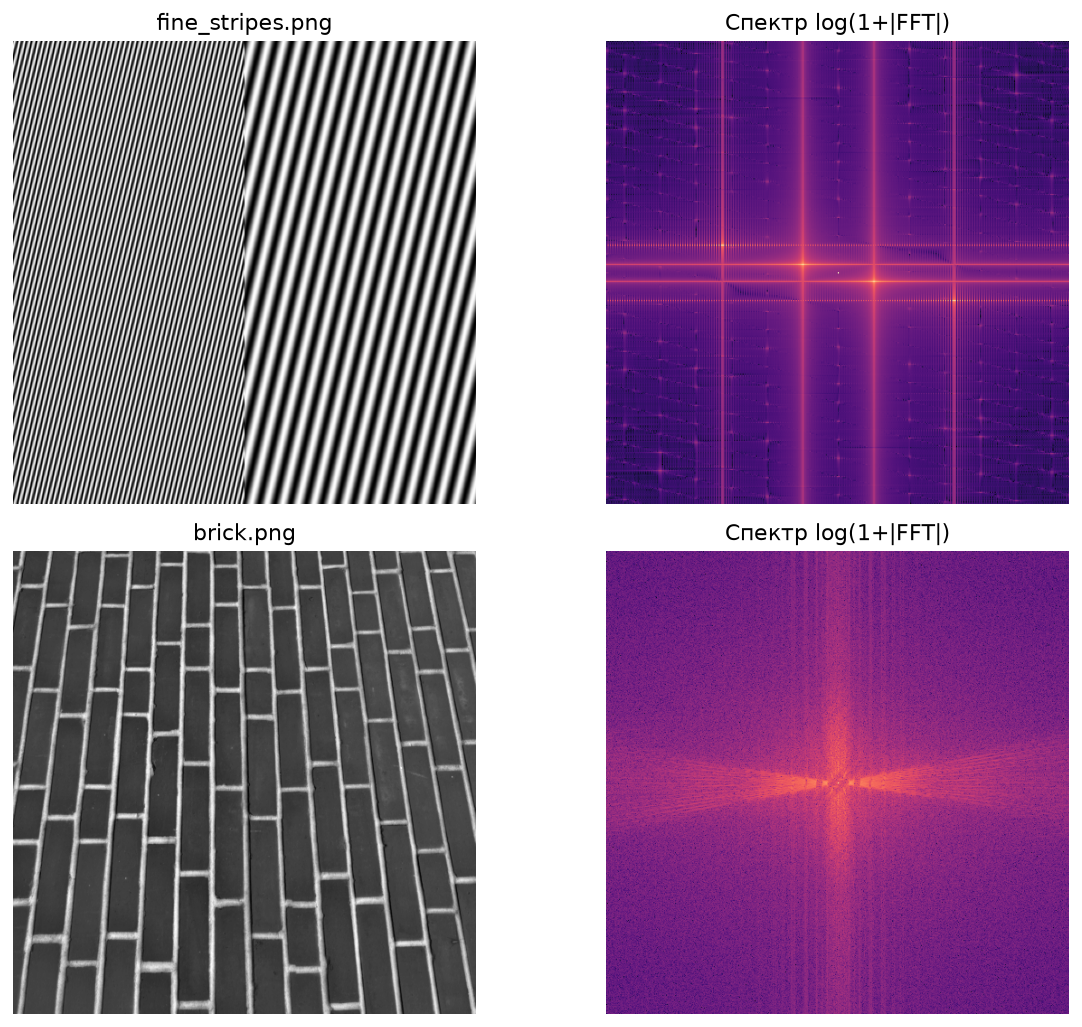

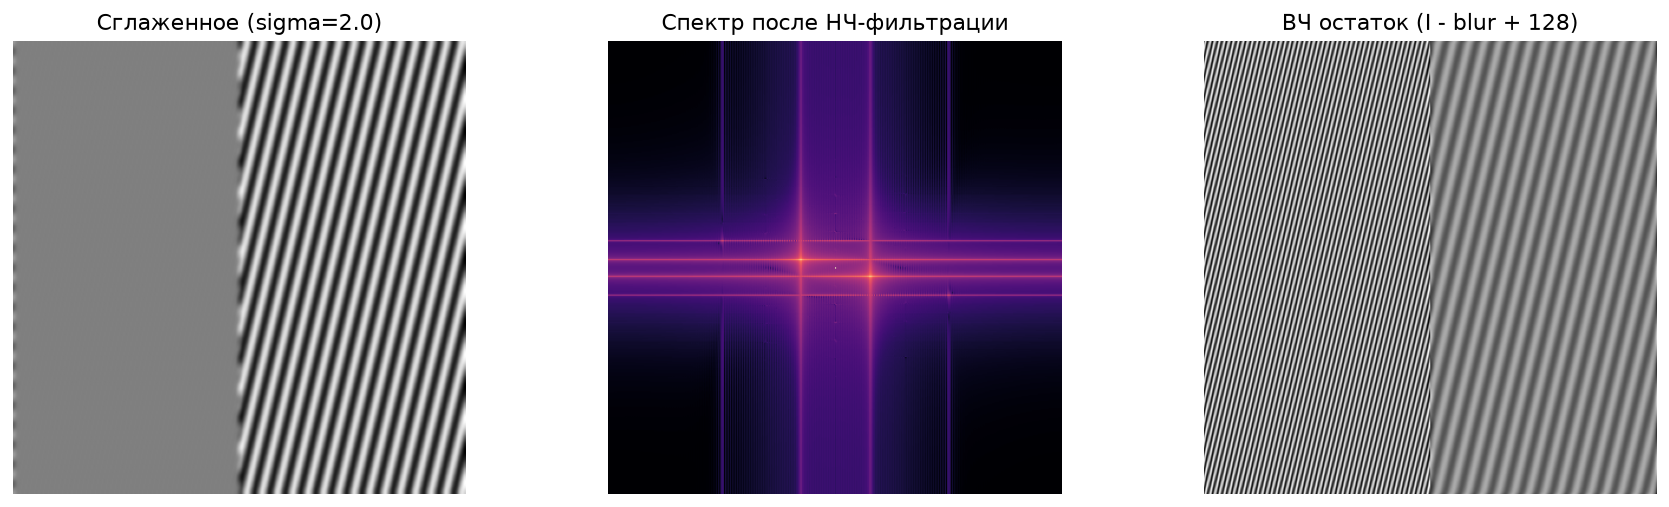

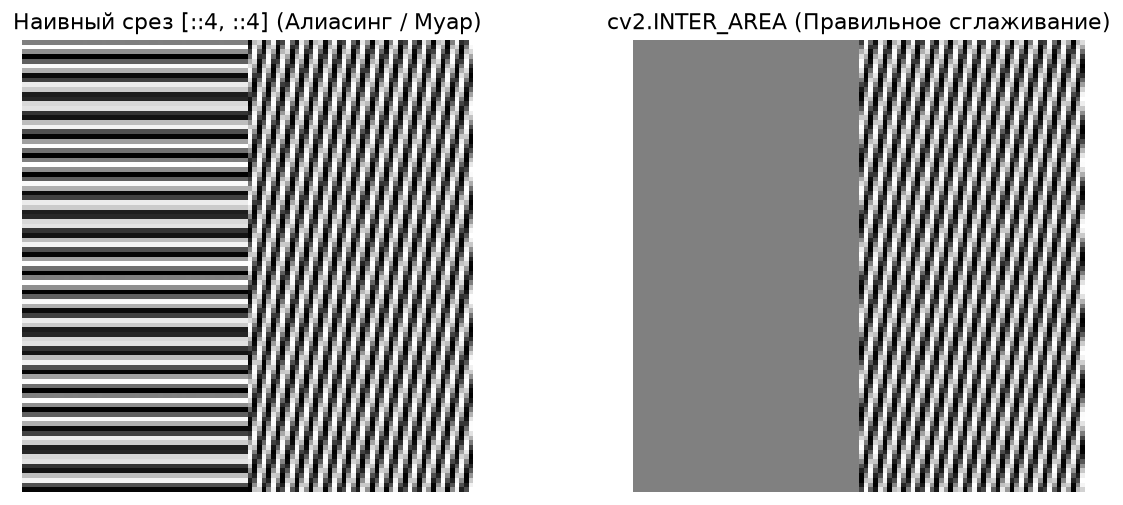

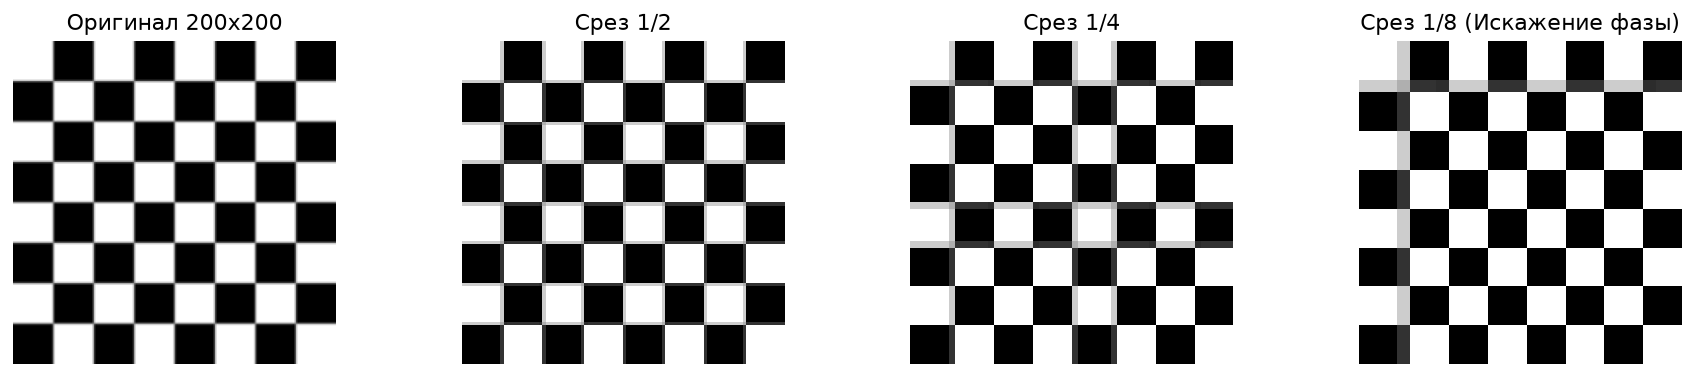

In [1]:
# Полное выполнение заданий Лабораторной работы №6
from pathlib import Path
import cv2, numpy as np, matplotlib.pyplot as plt

R = Path.cwd() if (Path.cwd()/'images').exists() else Path.cwd().parent
stripes = cv2.imread(str(R/'images/source/fine_stripes.png'), cv2.IMREAD_GRAYSCALE).astype(np.float32)
brick = cv2.imread(str(R/'images/source/brick.png'), cv2.IMREAD_GRAYSCALE).astype(np.float32)
check = cv2.imread(str(R/'images/source/checkerboard.png'), cv2.IMREAD_GRAYSCALE).astype(np.float32)
assert stripes is not None and brick is not None and check is not None

# 1. log(1 + |FFT|) для fine_stripes и brick
F_stripes = np.fft.fftshift(np.fft.fft2(stripes))
F_brick = np.fft.fftshift(np.fft.fft2(brick))

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes[0, 0].imshow(stripes, cmap='gray'); axes[0, 0].set_title("fine_stripes.png"); axes[0, 0].axis('off')
axes[0, 1].imshow(np.log1p(np.abs(F_stripes)), cmap='magma'); axes[0, 1].set_title("Спектр log(1+|FFT|)"); axes[0, 1].axis('off')
axes[1, 0].imshow(brick, cmap='gray'); axes[1, 0].set_title("brick.png"); axes[1, 0].axis('off')
axes[1, 1].imshow(np.log1p(np.abs(F_brick)), cmap='magma'); axes[1, 1].set_title("Спектр log(1+|FFT|)"); axes[1, 1].axis('off')
plt.tight_layout()
plt.show()

# 2-3. Гауссово сглаживание и высокочастотный остаток (unsharp mask)
blurred = cv2.GaussianBlur(stripes, (0, 0), sigmaX=2.0)
F_blurred = np.fft.fftshift(np.fft.fft2(blurred))
high_freq = stripes - blurred
high_freq_vis = np.clip(high_freq + 128.0, 0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(blurred, cmap='gray'); axes[0].set_title("Сглаженное (sigma=2.0)"); axes[0].axis('off')
axes[1].imshow(np.log1p(np.abs(F_blurred)), cmap='magma'); axes[1].set_title("Спектр после НЧ-фильтрации"); axes[1].axis('off')
axes[2].imshow(high_freq_vis, cmap='gray'); axes[2].set_title("ВЧ остаток (I - blur + 128)"); axes[2].axis('off')
plt.tight_layout()
plt.show()

# 4-5. Уменьшение в 4 раза: срез [::4, ::4] vs INTER_AREA (антиалиасинг)
down_naive = stripes[::4, ::4]
down_area = cv2.resize(stripes, (stripes.shape[1]//4, stripes.shape[0]//4), interpolation=cv2.INTER_AREA)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(down_naive, cmap='gray'); axes[0].set_title("Наивный срез [::4, ::4] (Алиасинг / Муар)"); axes[0].axis('off')
axes[1].imshow(down_area, cmap='gray'); axes[1].set_title("cv2.INTER_AREA (Правильное сглаживание)"); axes[1].axis('off')
plt.tight_layout()
plt.show()

# 6. Алиасинг шахматного поля при уменьшении в 2, 4, 8 раз
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
axes[0].imshow(check, cmap='gray'); axes[0].set_title("Оригинал 200x200"); axes[0].axis('off')
axes[1].imshow(check[::2, ::2], cmap='gray'); axes[1].set_title("Срез 1/2"); axes[1].axis('off')
axes[2].imshow(check[::4, ::4], cmap='gray'); axes[2].set_title("Срез 1/4"); axes[2].axis('off')
axes[3].imshow(check[::8, ::8], cmap='gray'); axes[3].set_title("Срез 1/8 (Искажение фазы)"); axes[3].axis('off')
plt.tight_layout()
plt.show()

print("""
[Контрольные вопросы]:
1) Гауссово сглаживание в пространственной области эквивалентно умножению на гауссиану в частотной области: высокие частоты экспоненциально затухают (low-pass filter).
2) Согласно теореме Котельникова-Найквиста, частоты выше половины частоты дискретизации безвозвратно теряются и вызывают наложение спектров (алиасинг); интерполяция лишь сглаживает пиксели.
""")


## Ваш результат

1. Вставьте итоговые графики/выводы и таблицы в отчёт.
2. Укажите версии пакетов, время выполнения, выбранные параметры.
3. Сделайте краткий вывод: что работало, где ошибка, почему?